## Setup and Sample Code

In [24]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.cm as cm
from scipy import misc
from sklearn.linear_model import LogisticRegression
from sklearn.multiclass import OneVsRestClassifier
from sklearn.metrics import accuracy_score
import warnings
import math

In [2]:
pd.set_option('display.max_columns', None)

In [3]:
warnings.filterwarnings("ignore")

(540, 2500) (540,)


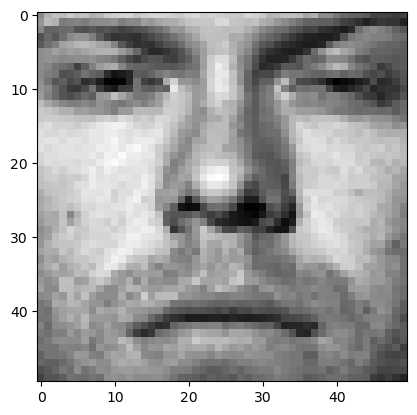

In [4]:
train_labels, train_data = [], []
for line in open('./faces/train.txt'):
    im = plt.imread(line.strip().split()[0])
    train_data.append(im.reshape(2500,))
    train_labels.append(line.strip().split()[1])
train_data, train_labels = np.array(train_data, dtype=float), np.array(train_labels, dtype=int)

print(train_data.shape, train_labels.shape)
plt.imshow(train_data[10, :].reshape(50,50), cmap = cm.Greys_r)
plt.show()

## (a) Download dataset
Datasets downloaded and put in faces folder

## (b) Load Train and Test

Load into X 

X shape = (540, 2500)

train_lables shape = (540,)

(540, 2500) (540,)


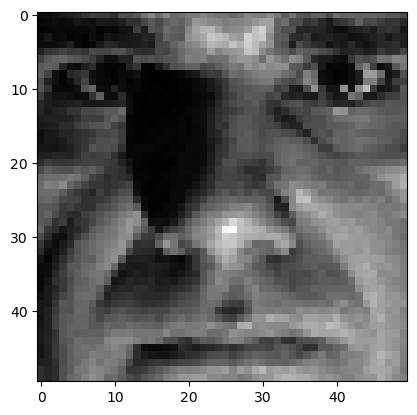

In [5]:
train_labels, X = [], []
for line in open('./faces/train.txt'):
    im = plt.imread(line.strip().split()[0])
    X.append(im.reshape(2500,))
    train_labels.append(line.strip().split()[1])
X, train_labels = np.array(train_data, dtype=float), np.array(train_labels, dtype=int)

print(X.shape, train_labels.shape)
plt.imshow(X[400, :].reshape(50,50), cmap = cm.Greys_r)
plt.show()

Test face load into X_test

X_test shape = (100, 2500)

test_lables shape = (100,)

(100, 2500) (100,)


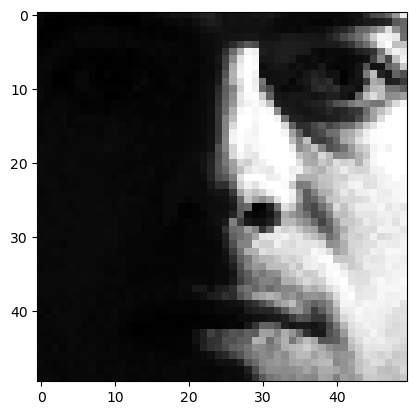

In [6]:
test_labels, X_test = [], []
for line in open('./faces/test.txt'):
    im = plt.imread(line.strip().split()[0])
    X_test.append(im.reshape(2500,))
    test_labels.append(line.strip().split()[1])
X_test, test_labels = np.array(X_test, dtype=float), np.array(test_labels, dtype=int)

print(X_test.shape, test_labels.shape)
plt.imshow(X_test[50, :].reshape(50,50), cmap = cm.Greys_r)
plt.show()

## (c) Average Face

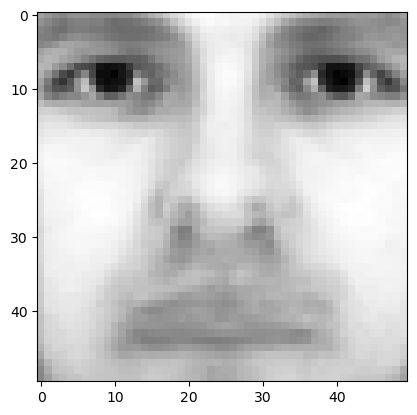

In [7]:
column_averages = X.mean(axis=0)
plt.imshow(column_averages.reshape(50,50), cmap = cm.Greys_r)
plt.show()

## (d) Mean Subtraction

Face after mean subtraction from train set:

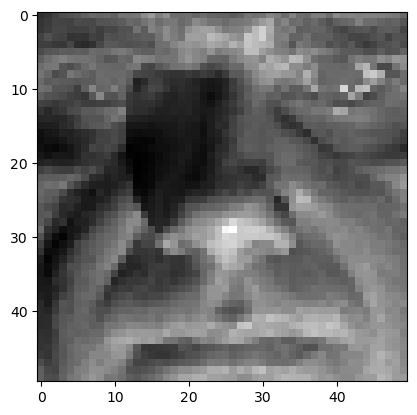

In [8]:
X = pd.DataFrame(X)
column_averages = pd.DataFrame(column_averages)
column_averages = column_averages.T
df_averages = pd.concat([column_averages] * len(X), ignore_index=True)

mean_subtracted = X - df_averages
mean_subtracted_array = mean_subtracted.values 

plt.imshow(mean_subtracted_array[400, :].reshape(50,50), cmap = cm.Greys_r)
plt.show()

Face before and after mean subtraction from test set:

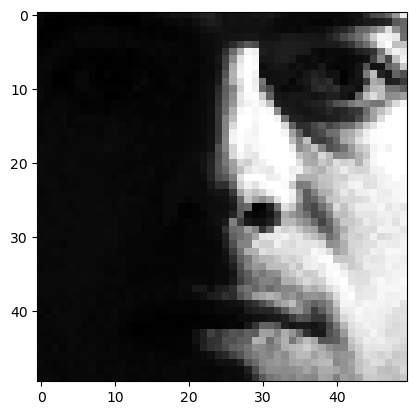

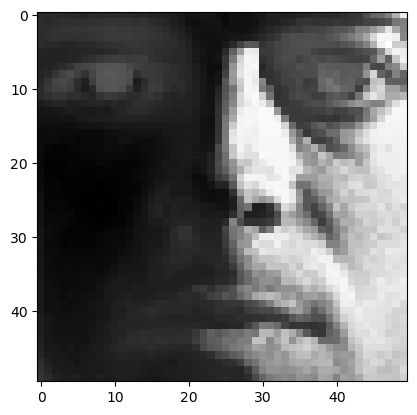

In [9]:
## subtract mean calculated in C from Xtest 

X_test_df = pd.DataFrame(X_test)
df_averages_test = pd.concat([column_averages] * len(X_test_df), ignore_index=True)

mean_subtracted_test = X_test_df - df_averages_test
mean_subtracted_test_array = mean_subtracted_test.values 

## same face before subtracting mean
plt.imshow(X_test[50, :].reshape(50,50), cmap = cm.Greys_r)
plt.show()

## same face after subtracting mean
plt.imshow(mean_subtracted_test_array[50, :].reshape(50,50), cmap = cm.Greys_r)
plt.show()

## (e) Eigenface
Eigendecomposition XTX and first 10 eigenfaces

Shape of VT: (2500, 2500)


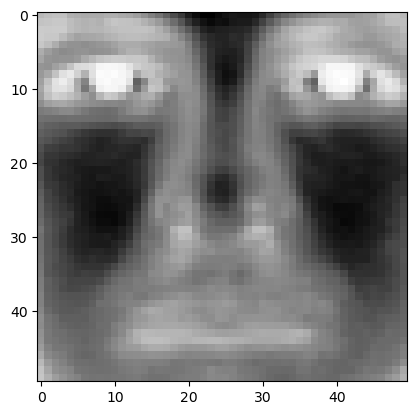

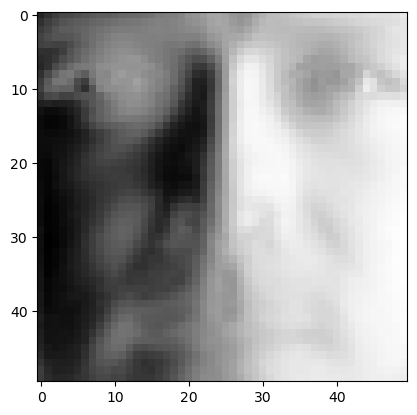

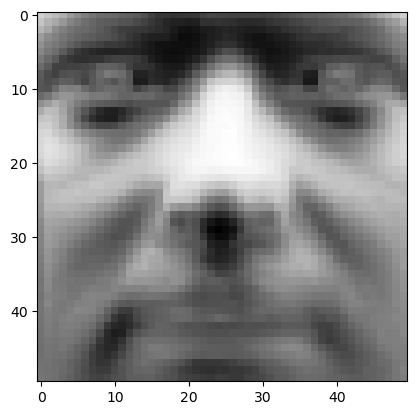

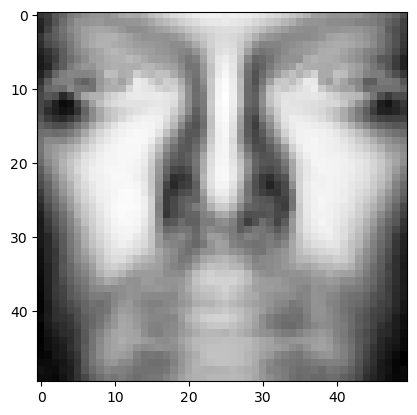

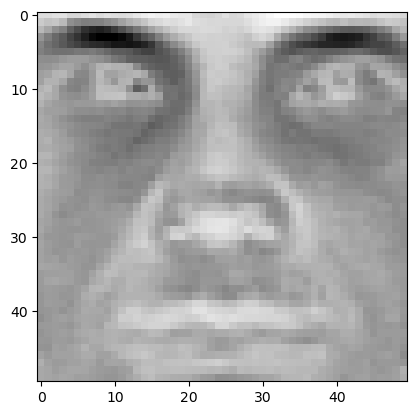

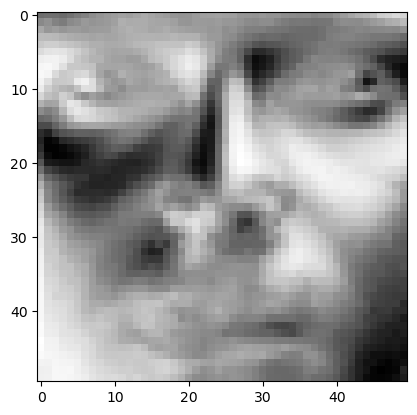

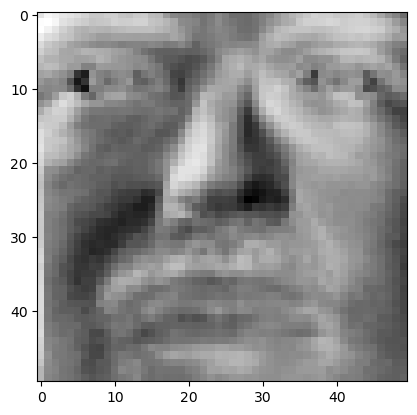

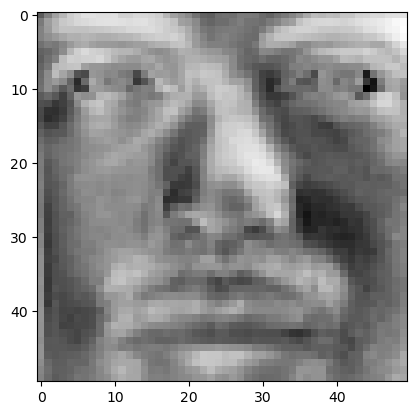

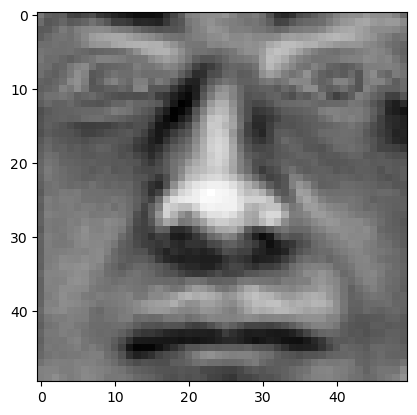

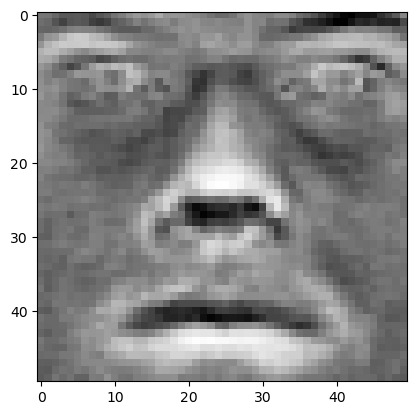

In [10]:
XTX = X.T @ X
eigenvalues, eigenvectors = np.linalg.eigh(XTX)

# Sort in descending order
idx = eigenvalues.argsort()[::-1]
eigenvalues = eigenvalues[idx]
eigenvectors = eigenvectors[:, idx]
VT = eigenvectors.T

print(f"Shape of VT: {VT.shape}") 
for i in range(10):
    plt.imshow(VT[i, :].reshape(50, 50), cmap=cm.Greys_r)
    plt.show()

## (f) Eigenface feature

In [29]:
def generate_eigenfeatures(X, Xtest, VT, r):
    VTr = VT[:r,:] 
    F = X @ VTr.T #multiply X to the transpose of first r rows of V T 
    Ftest = Xtest @ VTr.T
    return F, Ftest

In [12]:
#test generate_eigenfeatures
F, Ftest = generate_eigenfeatures(X, X_test, VT, 100)

In [28]:
print(f"r: {r}")
print(f"X shape: {X.shape}")
print(f"F shape: {F.shape}") #F should have same number of rows as X and r columns
print(f"Xtest shape: {X_test.shape}")
print(f"Ftest shape: {Ftest.shape}") #similarly for Xtest

r: 200
X shape: (540, 2500)
F shape: (540, 200)
Xtest shape: (100, 2500)
Ftest shape: (100, 200)


## (g) Face Recognition

Summary of results: 

Accuracy on test set with r=10: 0.81

Results on r = 1,2,...,200:

Best r = 124
Accuracy using best r = 0.99

In [44]:
F, Ftest = generate_eigenfeatures(X, X_test, VT, 10)

In [45]:
log_reg = LogisticRegression(multi_class='ovr', random_state = 42)
log_reg.fit(F, train_labels)

LogisticRegression(multi_class='ovr', random_state=42)

In [46]:
predictions = log_reg.predict(Ftest)

In [47]:
accuracy = accuracy_score(test_labels, predictions)
print(f"Accuracy on test set with r=10: {accuracy:.2f}")

Accuracy on test set with r=10: 0.81


In [39]:
accuracies = []
r_vals = range(1,201)
for r in r_vals:
    F, Ftest = generate_eigenfeatures(X, X_test, VT, r)
    log_reg = LogisticRegression(multi_class='ovr')
    log_reg.fit(F, train_labels)
    predictions = log_reg.predict(Ftest)
    accuracy = accuracy_score(test_labels, predictions)
    accuracies.append(accuracy)

#len(accuracies)

In [50]:
best_r = r_vals[np.argmax(accuracies)]
best_accuracy = max(accuracies)
print(f"\nBest r: {best_r}")
print(f"Best accuracy: {best_accuracy:.2f}")


Best r: 124
Best accuracy: 0.99


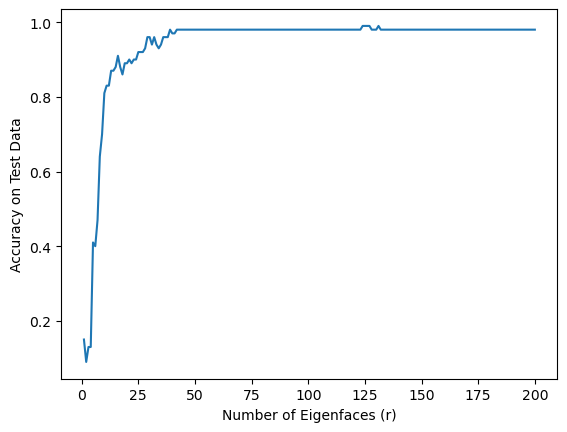

In [41]:
plt.plot(r_vals, accuracies)
plt.xlabel("Number of Eigenfaces (r)")
plt.ylabel("Accuracy on Test Data")
plt.show()

## (h) Low-Rank Data Loss

In [42]:
frobeniuses = []
r_vals = range(1,201)
for r in r_vals:
    F, Ftest = generate_eigenfeatures(X, X_test, VT, r)
    VTr = VT[:r,:]
    Xprime = F @ VTr
    XminusXprime = X - Xprime
    XminusXprimeT = XminusXprime.T
    frobenius = math.sqrt(np.trace(XminusXprimeT @ XminusXprime))
    frobeniuses.append(frobenius)

len(frobeniuses)

200

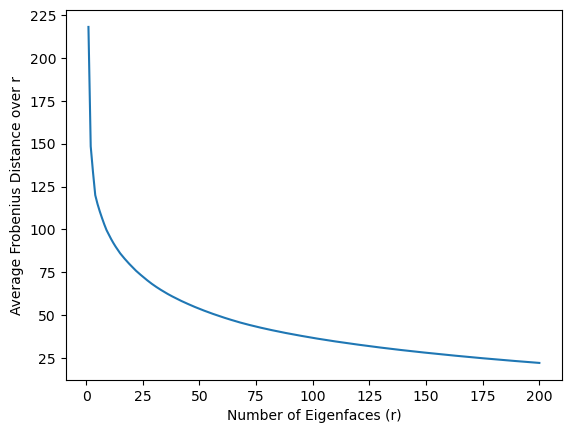

In [43]:
plt.plot(r_vals, frobeniuses)
plt.xlabel("Number of Eigenfaces (r)")
plt.ylabel("Average Frobenius Distance over r")
plt.show()